# Projet de démonstration : peut-on s'enrichir sans émettre plus de CO₂ ?

Ce notebook est un **exemple complet** de projet d'analyse de données, du choix du dataset jusqu'aux conclusions. Il suit les trois piliers du projet :

1. **Récupérer un dataset** (sections 1 et 2)
2. **Appliquer les méthodes du cours** (sections 3 à 10 : nettoyage, exploration, corrélation, régression, ACP, clustering, random forest)
3. **Préparer le storytelling** (section 11 : les messages clés qui alimentent la présentation)

> Lisez les cellules Markdown autant que le code : c'est le raisonnement qui compte.

## 0. Problématique

**Question principale** : la croissance économique d'un pays implique-t-elle forcément une hausse de ses émissions de CO₂ ?

**Sous-questions** :
- Les pays riches émettent-ils plus de CO₂ par habitant que les pays pauvres, et dans quelle proportion ?
- Certains pays ont-ils réussi à faire croître leur PIB tout en réduisant leurs émissions (« découplage ») ?
- Ce découplage est-il réel, ou s'explique-t-il par la délocalisation de la production polluante ?
- Quels profils de pays existent, et peut-on prédire lesquels vont découpler ?

## 1. Trouver et documenter le dataset

**Démarche de recherche** : on cherche des données d'émissions de CO₂ **et** de PIB, par pays et par année. Our World in Data (OWID) publie un jeu de données qui réunit les deux, documenté et mis à jour chaque année.

| Élément | Valeur |
| --- | --- |
| Source | Our World in Data, *CO₂ and Greenhouse Gas Emissions* |
| Lien | https://github.com/owid/co2-data |
| Sources primaires | Global Carbon Project (émissions), Maddison Project (PIB), ONU (population) |
| Licence | CC-BY 4.0 (réutilisation libre en citant la source) |
| Documentation | fichier `owid-co2-codebook.csv` dans le dépôt |
| Format | CSV, une ligne par pays et par année |

**Pourquoi ce dataset ?** Il est volumineux (≈ 50 000 lignes, ≈ 80 colonnes), documenté, couvre plus de 200 pays et contient de vrais défauts à traiter (valeurs manquantes, agrégats mélangés aux pays).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import os

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
os.makedirs("figures", exist_ok=True)

URL = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
try:
    df_raw = pd.read_csv("co2.csv")      # copie locale si elle existe
except FileNotFoundError:
    df_raw = pd.read_csv(URL)            # sinon, téléchargement direct
    df_raw.to_csv("co2.csv", index=False)

df_raw.shape

(50411, 79)

## 2. Premier contact avec les données

Avant toute analyse : quelles colonnes, quels types, quelle période, quelles valeurs manquantes ?

In [2]:
df_raw[["country", "year", "iso_code", "population", "gdp", "co2", "co2_per_capita", "consumption_co2"]].head()

,country,year,iso_code,population,gdp,co2,co2_per_capita,consumption_co2
0,Afghanistan,1750,AFG,2802560.0,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,NaN,NaN,NaN


In [3]:
print("Période couverte :", df_raw["year"].min(), "→", df_raw["year"].max())
print("Nombre d'entités :", df_raw["country"].nunique())
df_raw[["population", "gdp", "co2", "co2_per_capita", "consumption_co2", "energy_per_capita"]].describe().T

Période couverte : 1750 → 2024
Nombre d'entités : 254


,count,mean,std,min,25%,50%,75%,max
population,41167.0,6.017294e+07,3.308412e+08,215.0,3.272140e+05,2.291264e+06,9.986553e+06,8.161973e+09
gdp,15251.0,3.300495e+11,3.086383e+12,49980000.0,7.874038e+09,2.743861e+10,1.212627e+11,1.301126e+14
co2,29384.0,4.202270e+02,1.972092e+03,0.0,3.810000e-01,5.081000e+00,5.365650e+01,3.859858e+04
co2_per_capita,26509.0,3.821411e+00,1.431286e+01,0.0,1.710000e-01,1.023000e+00,4.327000e+00,7.827430e+02
consumption_co2,5053.0,1.318130e+03,3.904105e+03,0.0,1.207900e+01,7.433600e+01,4.548130e+02,3.859858e+04
energy_per_capita,10586.0,2.421802e+04,3.220352e+04,0.0,2.703231e+03,1.179296e+04,3.522545e+04,3.185597e+05


On ne garde que les variables utiles à notre question. Signification (d'après le codebook) :

| Variable | Signification | Unité |
| --- | --- | --- |
| `co2` | Émissions territoriales de CO₂ (produites sur le sol du pays) | millions de tonnes |
| `consumption_co2` | Émissions liées à la **consommation** du pays (importations incluses, exportations exclues) | millions de tonnes |
| `gdp` | PIB en dollars internationaux constants (Maddison) | dollars 2011 |
| `population` | Population | habitants |
| `co2_per_capita` | CO₂ territorial par habitant | tonnes |
| `energy_per_capita` | Consommation d'énergie primaire par habitant | kWh |
| `coal_co2` | Part du CO₂ issue du charbon | millions de tonnes |

## 3. Nettoyage

### 3.1 Un piège classique : des agrégats mélangés aux pays

Le nombre d'entités (> 250) est supérieur au nombre de pays dans le monde. Regardons les entités sans code ISO ou avec un code commençant par `OWID_` :

In [4]:
agregats = df_raw[df_raw["iso_code"].isna() | df_raw["iso_code"].str.startswith("OWID", na=False)]["country"].unique()
print(len(agregats), "entités qui ne sont pas des pays, par exemple :")
print(sorted(agregats)[:20])

36 entités qui ne sont pas des pays, par exemple :
['Africa', 'Africa (GCP)', 'Asia', 'Asia (GCP)', 'Asia (excl. China and India)', 'Central America (GCP)', 'Europe', 'Europe (GCP)', 'Europe (excl. EU-27)', 'Europe (excl. EU-28)', 'European Union (27)', 'European Union (28)', 'High-income countries', 'International aviation', 'International shipping', 'Kosovo', 'Kuwaiti Oil Fires', 'Kuwaiti Oil Fires (GCP)', 'Least developed countries (Jones et al.)', 'Low-income countries']


« World », « Europe », « High-income countries »… Si on les gardait, la moyenne et les corrélations seraient faussées (le monde compterait comme un pays !). On les retire, mais on garde « World » à part pour la tendance mondiale. Remarque : ce filtre retire aussi le Kosovo (code `OWID_KOS`), un choix à mentionner dans les limites.

In [5]:
monde = df_raw[df_raw["country"] == "World"].copy()

colonnes = ["country", "year", "iso_code", "population", "gdp", "co2", "co2_per_capita",
            "consumption_co2", "energy_per_capita", "coal_co2", "oil_co2", "gas_co2"]
pays = df_raw.loc[~df_raw["country"].isin(agregats), colonnes].copy()

print("Lignes avant :", len(df_raw), "| après retrait des agrégats :", len(pays))
print("Nombre de pays :", pays["country"].nunique())

Lignes avant : 50411 | après retrait des agrégats : 42480
Nombre de pays : 218


### 3.2 Valeurs manquantes

Le PIB et les émissions de consommation ne sont pas disponibles pour toutes les années. Regardons la couverture par année :

In [6]:
couverture = (pays[pays["year"] >= 1990]
              .groupby("year")[["co2", "gdp", "consumption_co2"]]
              .apply(lambda g: g.notna().sum()))
couverture.tail(6)

,co2,gdp,consumption_co2
year,,,
2019,215,164,120
2020,215,164,120
2021,215,164,120
2022,215,164,120
2023,215,0,120
2024,215,0,0


**Décision** : le PIB s'arrête en 2022. On travaillera donc sur **2022** pour les comparaisons entre pays, et sur **2005 → 2022** pour les évolutions (17 ans, après le protocole de Kyoto). Les pays sans PIB sont exclus des analyses qui en ont besoin : on le signale comme limite.

### 3.3 Variables dérivées

In [7]:
pays["pib_par_hab"] = pays["gdp"] / pays["population"]
pays["part_charbon"] = pays["coal_co2"] / pays["co2"]

annee = 2022
p22 = pays[(pays["year"] == annee)].dropna(subset=["pib_par_hab", "co2_per_capita"])
p22 = p22[p22["co2_per_capita"] > 0]
print(f"{len(p22)} pays avec PIB et CO₂ en {annee}")

164 pays avec PIB et CO₂ en 2022


## 4. Exploration

### 4.1 La tendance mondiale

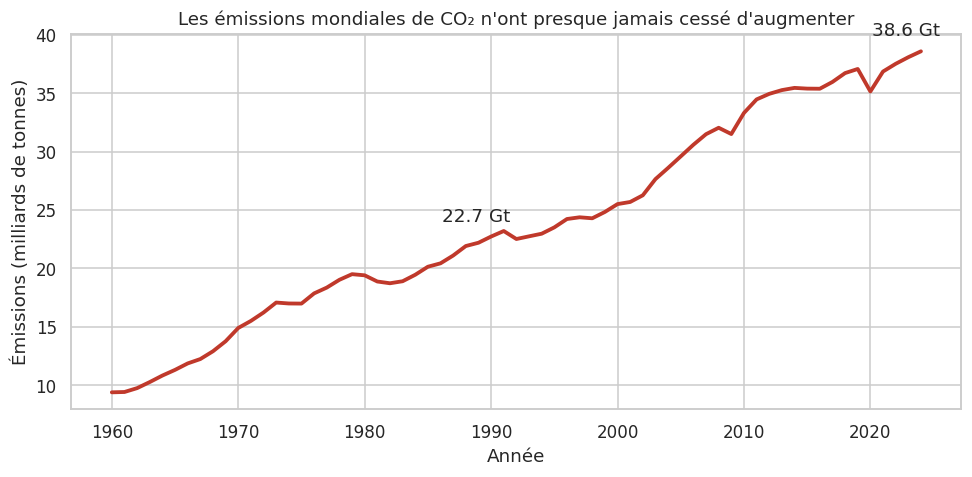

Hausse 1990 → 2024 : +70 %


In [8]:
m = monde[monde["year"] >= 1960]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(m["year"], m["co2"] / 1000, color="#c0392b", lw=2.5)
ax.set_title("Les émissions mondiales de CO₂ n'ont presque jamais cessé d'augmenter")
ax.set_xlabel("Année"); ax.set_ylabel("Émissions (milliards de tonnes)")
for a in [1990, 2024]:
    v = m.loc[m["year"] == a, "co2"].iloc[0] / 1000
    ax.annotate(f"{v:.1f} Gt", (a, v), textcoords="offset points", xytext=(-10, 10), ha="center")
plt.tight_layout(); plt.savefig("figures/01_tendance_mondiale.png", dpi=200); plt.show()

v90 = monde.loc[monde.year == 1990, "co2"].iloc[0]; v24 = monde.loc[monde.year == 2024, "co2"].iloc[0]
print(f"Hausse 1990 → 2024 : +{(v24 / v90 - 1) * 100:.0f} %")

### 4.2 Qui émet ? Total contre par habitant

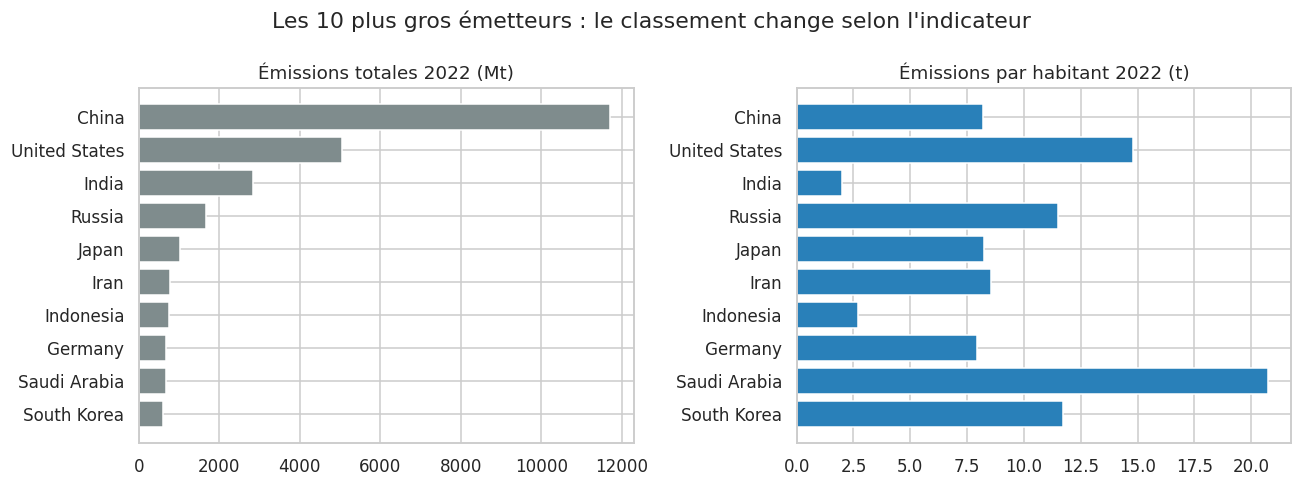

In [9]:
top = p22.nlargest(10, "co2").sort_values("co2")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(top["country"], top["co2"], color="#7f8c8d")
axes[0].set_title("Émissions totales 2022 (Mt)")
axes[1].barh(top["country"], top["co2_per_capita"], color="#2980b9")
axes[1].set_title("Émissions par habitant 2022 (t)")
plt.suptitle("Les 10 plus gros émetteurs : le classement change selon l'indicateur")
plt.tight_layout(); plt.show()

La Chine émet plus que les États-Unis au total, mais un Américain émet presque deux fois plus qu'un Chinois. **Le choix de l'indicateur change l'histoire** : pour comparer des pays de tailles différentes, on raisonne par habitant.

### 4.3 Distribution des émissions par habitant

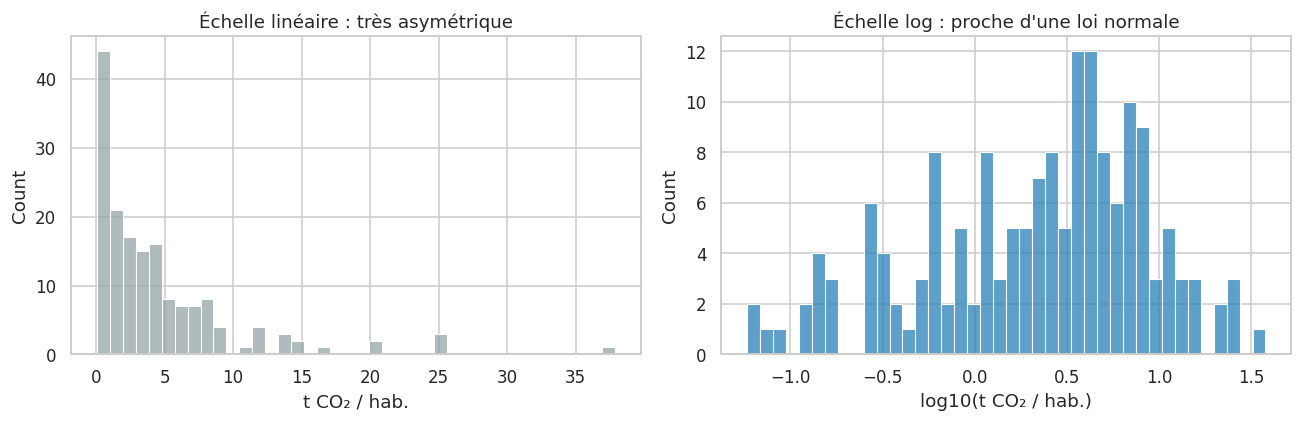

Skewness linéaire : 2.71 | après log : -0.54


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(p22["co2_per_capita"], bins=40, ax=axes[0], color="#95a5a6")
axes[0].set_title("Échelle linéaire : très asymétrique"); axes[0].set_xlabel("t CO₂ / hab.")
sns.histplot(np.log10(p22["co2_per_capita"]), bins=40, ax=axes[1], color="#2980b9")
axes[1].set_title("Échelle log : proche d'une loi normale"); axes[1].set_xlabel("log10(t CO₂ / hab.)")
plt.tight_layout(); plt.show()
print("Skewness linéaire :", round(stats.skew(p22["co2_per_capita"]), 2),
      "| après log :", round(stats.skew(np.log10(p22["co2_per_capita"])), 2))

La distribution est très asymétrique (quelques pays pétroliers à plus de 20 t/hab.). **Le passage au logarithme** la rend symétrique : c'est ce qu'on utilisera pour les corrélations et la régression.

## 5. Richesse et émissions : corrélation et régression

In [11]:
x = np.log10(p22["pib_par_hab"]); y = np.log10(p22["co2_per_capita"])
r, p = stats.pearsonr(x, y)
rho, p_s = stats.spearmanr(p22["pib_par_hab"], p22["co2_per_capita"])
print(f"Pearson (log-log) : r = {r:.2f} (p = {p:.1e})")
print(f"Spearman          : rho = {rho:.2f} (p = {p_s:.1e})")

Pearson (log-log) : r = 0.91 (p = 1.0e-62)
Spearman          : rho = 0.89 (p = 1.1e-57)


log10(CO₂/hab) = 1.04 × log10(PIB/hab) -3.87   R² = 0.82


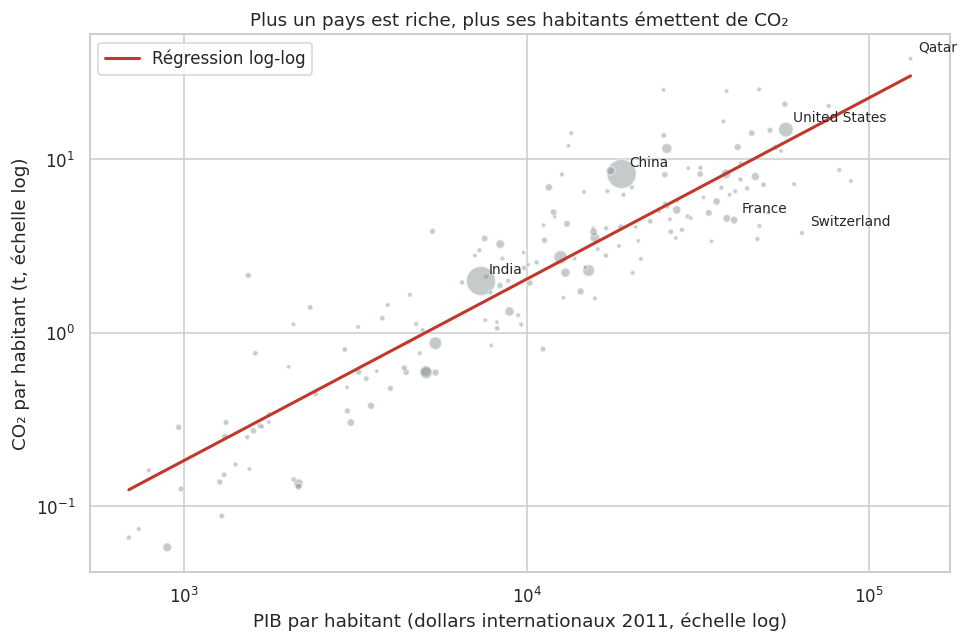

In [12]:
reg = stats.linregress(x, y)
print(f"log10(CO₂/hab) = {reg.slope:.2f} × log10(PIB/hab) {reg.intercept:+.2f}   R² = {reg.rvalue**2:.2f}")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(p22["pib_par_hab"], p22["co2_per_capita"], s=p22["population"] / 4e6 + 8,
           alpha=0.45, color="#7f8c8d", edgecolor="white")
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(10**xs, 10**(reg.intercept + reg.slope * xs), color="#c0392b", lw=2, label="Régression log-log")
for nom in ["France", "United States", "China", "India", "Qatar", "Switzerland"]:
    row = p22[p22["country"] == nom].iloc[0]
    ax.annotate(nom, (row["pib_par_hab"], row["co2_per_capita"]), fontsize=9,
                xytext=(5, 5), textcoords="offset points")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("PIB par habitant (dollars internationaux 2011, échelle log)")
ax.set_ylabel("CO₂ par habitant (t, échelle log)")
ax.set_title("Plus un pays est riche, plus ses habitants émettent de CO₂")
ax.legend(); plt.tight_layout(); plt.savefig("figures/02_richesse_co2.png", dpi=200); plt.show()

**Interprétation** :
- La relation est très forte (r ≈ 0,9) et significative.
- La pente est proche de **1** : en moyenne, quand le PIB par habitant est multiplié par 10, les émissions par habitant sont aussi multipliées par environ 10.
- Mais à niveau de richesse égal, les écarts restent importants (la France émet bien moins que les États-Unis). Le mix énergétique (nucléaire, charbon…) joue un rôle.

⚠️ **Corrélation n'est pas causalité** : cette coupe transversale compare des pays différents à un instant donné. Elle ne dit pas ce qui se passe quand **un même pays** s'enrichit. Pour cela, il faut regarder les évolutions dans le temps.

## 6. Le découplage : s'enrichir en émettant moins ?

On compare, pour chaque pays, l'évolution du PIB et des émissions entre 2005 et 2022. On distingue :
- **découplage absolu** : PIB en hausse, CO₂ en baisse ;
- **découplage relatif** : le CO₂ augmente, mais moins vite que le PIB ;
- **aucun découplage** : le CO₂ augmente au moins aussi vite que le PIB.

In [13]:
evol = (pays[pays["year"].isin([2005, 2022])]
        .pivot(index="country", columns="year", values=["gdp", "co2", "consumption_co2"]))
evol = evol.dropna(subset=[("gdp", 2005), ("gdp", 2022), ("co2", 2005), ("co2", 2022)])

d = pd.DataFrame({
    "var_pib": (evol["gdp"][2022] / evol["gdp"][2005] - 1) * 100,
    "var_co2": (evol["co2"][2022] / evol["co2"][2005] - 1) * 100,
    "var_co2_conso": (evol["consumption_co2"][2022] / evol["consumption_co2"][2005] - 1) * 100,
})

def categorie(row):
    if row["var_pib"] <= 0: return "PIB en baisse"
    if row["var_co2"] < 0: return "Découplage absolu"
    if row["var_co2"] < row["var_pib"]: return "Découplage relatif"
    return "Aucun découplage"

d["categorie"] = d.apply(categorie, axis=1)
d["categorie"].value_counts()

categorie
Découplage relatif    70
Découplage absolu     45
Aucun découplage      41
PIB en baisse          8
Name: count, dtype: int64

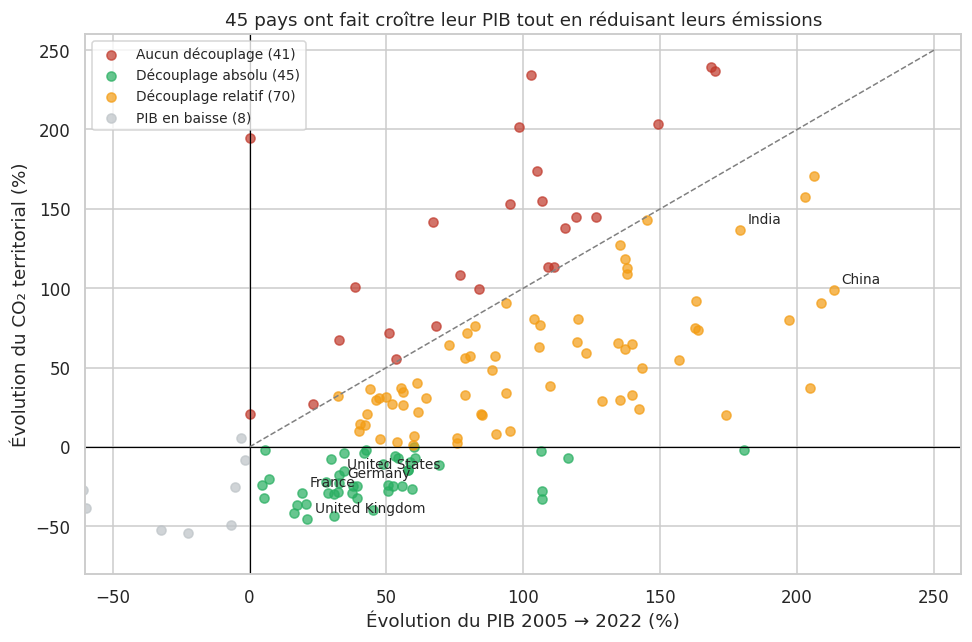

In [14]:
couleurs = {"Découplage absolu": "#27ae60", "Découplage relatif": "#f39c12",
            "Aucun découplage": "#c0392b", "PIB en baisse": "#bdc3c7"}
fig, ax = plt.subplots(figsize=(9, 6))
for cat, g in d.groupby("categorie"):
    ax.scatter(g["var_pib"], g["var_co2"], label=f"{cat} ({len(g)})", color=couleurs[cat], alpha=0.7)
ax.axhline(0, color="black", lw=0.8); ax.axvline(0, color="black", lw=0.8)
ax.plot([0, 250], [0, 250], ls="--", color="grey", lw=1)
for nom in ["France", "United Kingdom", "Germany", "United States", "China", "India"]:
    ax.annotate(nom, (d.loc[nom, "var_pib"], d.loc[nom, "var_co2"]), fontsize=9, xytext=(5, 4), textcoords="offset points")
ax.set_xlim(-60, 260); ax.set_ylim(-80, 260)
ax.set_xlabel("Évolution du PIB 2005 → 2022 (%)"); ax.set_ylabel("Évolution du CO₂ territorial (%)")
ax.set_title("45 pays ont fait croître leur PIB tout en réduisant leurs émissions")
ax.legend(loc="upper left", fontsize=9); plt.tight_layout()
plt.savefig("figures/03_decouplage.png", dpi=200); plt.show()

In [15]:
d.loc[["France", "Germany", "United Kingdom", "United States", "China", "India"]].round(0)

,var_pib,var_co2,var_co2_conso,categorie
country,,,,
France,19.0,-29.0,-20.0,Découplage absolu
Germany,33.0,-23.0,-20.0,Découplage absolu
United Kingdom,21.0,-45.0,-34.0,Découplage absolu
United States,33.0,-17.0,-16.0,Découplage absolu
China,213.0,99.0,124.0,Découplage relatif
India,179.0,137.0,112.0,Découplage relatif


## 7. Le piège des émissions « importées »

Les émissions **territoriales** ne comptent que ce qui est produit sur le sol du pays. Si un pays délocalise ses usines et importe les produits, ses émissions territoriales baissent… sans que la pollution liée à sa consommation diminue. Vérifions avec les émissions **de consommation**.

In [16]:
absolus = d[(d["categorie"] == "Découplage absolu") & d["var_co2_conso"].notna()]
reel = (absolus["var_co2_conso"] < 0).sum()
print(f"{len(absolus)} pays en découplage absolu avec données de consommation")
print(f"→ {reel} voient aussi baisser leurs émissions de consommation")
print(f"→ {len(absolus) - reel} ne baissent qu'en émissions territoriales")

39 pays en découplage absolu avec données de consommation
→ 27 voient aussi baisser leurs émissions de consommation
→ 12 ne baissent qu'en émissions territoriales


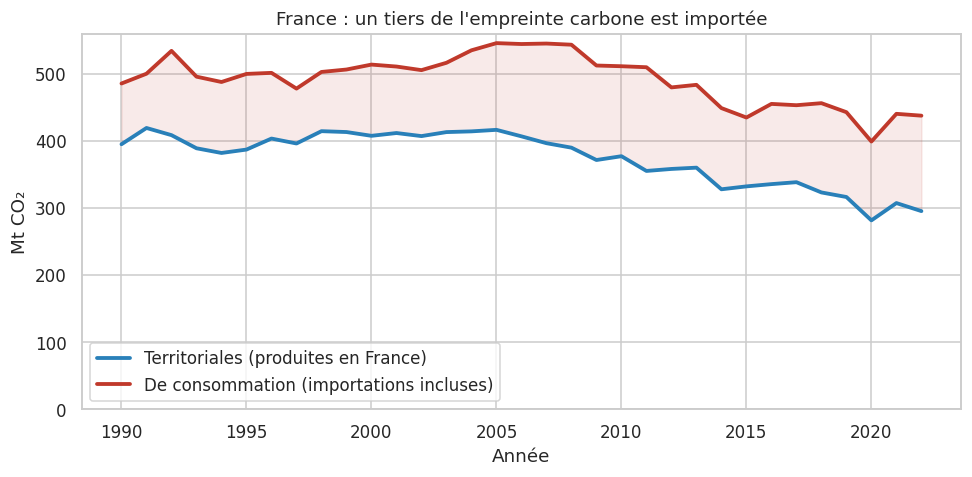

2022 : territorial 295 Mt, consommation 437 Mt → 32 % importé


In [17]:
fr = pays[(pays["country"] == "France") & (pays["year"].between(1990, 2022))]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(fr["year"], fr["co2"], label="Territoriales (produites en France)", color="#2980b9", lw=2.5)
ax.plot(fr["year"], fr["consumption_co2"], label="De consommation (importations incluses)", color="#c0392b", lw=2.5)
ax.fill_between(fr["year"], fr["co2"], fr["consumption_co2"], color="#c0392b", alpha=0.1)
ax.set_ylim(0); ax.set_ylabel("Mt CO₂"); ax.set_xlabel("Année")
ax.set_title("France : un tiers de l'empreinte carbone est importée")
ax.legend(); plt.tight_layout(); plt.savefig("figures/04_france_import.png", dpi=200); plt.show()

f22 = fr[fr.year == 2022].iloc[0]
print(f"2022 : territorial {f22.co2:.0f} Mt, consommation {f22.consumption_co2:.0f} Mt "
      f"→ {(1 - f22.co2 / f22.consumption_co2) * 100:.0f} % importé")

**Interprétation** : pour la majorité des pays en découplage absolu, la baisse est aussi visible en émissions de consommation : le découplage n'est donc pas qu'un effet de délocalisation. En revanche, pour près d'un tiers d'entre eux (12 sur 39), la baisse n'apparaît qu'en territorial. En France, les émissions de consommation baissent aussi, mais moins vite que les émissions territoriales.

## 8. Analyse en composantes principales (ACP)

On veut maintenant décrire les **profils** des pays en 2022 à partir de plusieurs variables à la fois : richesse, émissions, énergie et mix fossile. Avec 5 variables, impossible de tout visualiser d'un coup : l'ACP résume l'information en quelques axes.

**Choix des variables** : les parts de charbon, pétrole et gaz dans le CO₂ sont presque complémentaires (leur somme est proche de 100 %). Les garder toutes les trois créerait une redondance quasi parfaite : on retire la part du pétrole.

**Autre piège** : l'intensité carbone du PIB (CO₂ / PIB) est exactement égale à (CO₂ / habitant) / (PIB / habitant). En logarithme, c'est une simple différence de deux variables déjà présentes : l'ajouter n'apporterait aucune information et créerait un axe de variance nulle. On ne la garde pas.

In [18]:
pays["part_petrole"] = pays["oil_co2"] / pays["co2"]
pays["part_gaz"] = pays["gas_co2"] / pays["co2"]

base = pays[pays["year"] == 2022].set_index("country")
with np.errstate(divide="ignore"):   # log10(0) donne -inf : ces lignes sont retirées juste après
    acp_df = pd.DataFrame({
        "log_pib_hab": np.log10(base["pib_par_hab"]),
        "log_co2_hab": np.log10(base["co2_per_capita"]),
        "log_energie_hab": np.log10(base["energy_per_capita"]),
        "part_charbon": base["part_charbon"],
        "part_gaz": base["part_gaz"],
    }).replace([np.inf, -np.inf], np.nan).dropna()
print(f"{len(acp_df)} pays avec les 5 variables renseignées")

X_acp = StandardScaler().fit_transform(acp_df)   # indispensable : les variables n'ont pas la même unité
acp = PCA().fit(X_acp)
coords = pd.DataFrame(acp.transform(X_acp)[:, :3], index=acp_df.index, columns=["CP1", "CP2", "CP3"])

106 pays avec les 5 variables renseignées


### 8.1 Combien d'axes garder ?

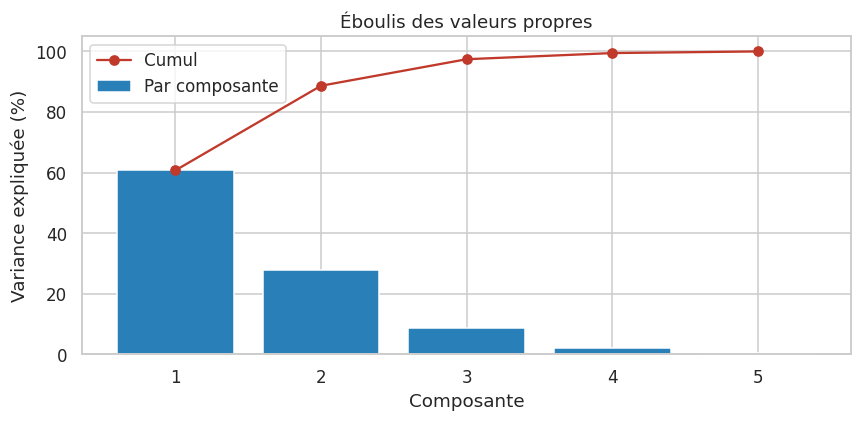

Variance expliquée (%) : [60.7 28.   8.8  2.   0.5] | cumul 2 axes : 88.7 | cumul 3 axes : 97.4


In [19]:
var = acp.explained_variance_ratio_ * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(var) + 1), var, color="#2980b9", label="Par composante")
ax.plot(range(1, len(var) + 1), var.cumsum(), color="#c0392b", marker="o", label="Cumul")
ax.set_xlabel("Composante"); ax.set_ylabel("Variance expliquée (%)")
ax.set_title("Éboulis des valeurs propres"); ax.legend(); plt.tight_layout(); plt.show()
print("Variance expliquée (%) :", var.round(1), "| cumul 2 axes :", var[:2].sum().round(1), "| cumul 3 axes :", var[:3].sum().round(1))

On regarde où la courbe « casse » (critère du coude) et le cumul de variance. Les deux premiers axes suffisent pour une représentation en plan ; on gardera trois axes pour le clustering.

### 8.2 Cercle des corrélations : que signifient les axes ?

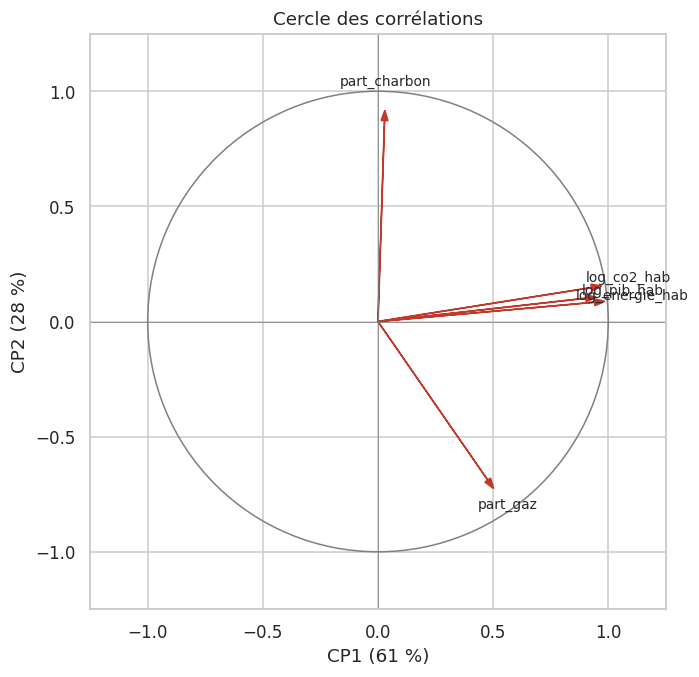

,CP1,CP2
log_pib_hab,0.95,0.11
log_co2_hab,0.97,0.15
log_energie_hab,0.99,0.09
part_charbon,0.03,0.92
part_gaz,0.50,-0.73


In [20]:
charges = pd.DataFrame(acp.components_[:2].T * np.sqrt(acp.explained_variance_[:2]),
                       index=acp_df.columns, columns=["CP1", "CP2"])
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for var_nom, (a, b) in charges.iterrows():
    ax.arrow(0, 0, a, b, head_width=0.03, color="#c0392b", length_includes_head=True)
    ax.text(a * 1.12, b * 1.12, var_nom, ha="center", fontsize=9)
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.25, 1.25); ax.set_aspect("equal")
ax.set_xlabel(f"CP1 ({var[0]:.0f} %)"); ax.set_ylabel(f"CP2 ({var[1]:.0f} %)")
ax.set_title("Cercle des corrélations"); plt.tight_layout(); plt.show()
charges.round(2)

**Lecture** (à vérifier sur le cercle et le tableau des corrélations) :
- **CP1** regroupe richesse, énergie et émissions par habitant : c'est un axe de **niveau de développement**.
- **CP2** oppose la part du charbon à la part du gaz : c'est un axe de **mix énergétique**.

L'ACP confirme que deux pays également riches peuvent avoir des profils d'émissions très différents selon leur mix.

### 8.3 Les pays dans le plan factoriel

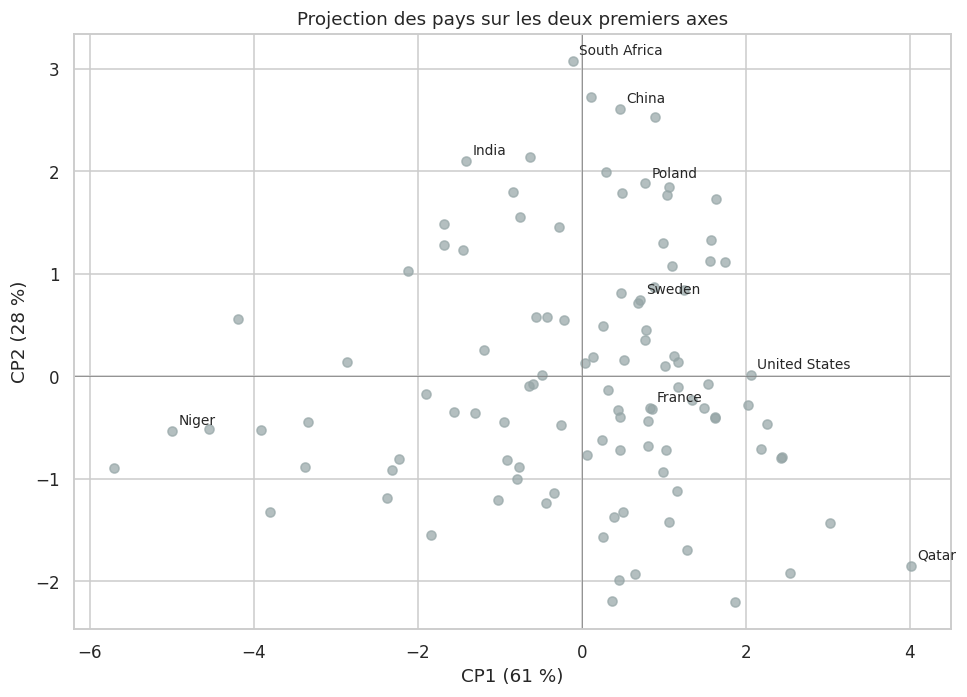

In [21]:
etiquettes = ["France", "United States", "China", "India", "Poland", "Qatar", "Sweden", "South Africa", "Niger"]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(coords["CP1"], coords["CP2"], color="#95a5a6", alpha=0.7)
for nom in etiquettes:
    if nom in coords.index:
        ax.annotate(nom, (coords.loc[nom, "CP1"], coords.loc[nom, "CP2"]), fontsize=9, xytext=(4, 4), textcoords="offset points")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel(f"CP1 ({var[0]:.0f} %)"); ax.set_ylabel(f"CP2 ({var[1]:.0f} %)")
ax.set_title("Projection des pays sur les deux premiers axes"); plt.tight_layout(); plt.show()

## 9. Clustering : une typologie des pays

On regroupe maintenant les pays qui se ressemblent avec **K-means**, appliqué aux trois premières composantes de l'ACP (elles résument l'essentiel de l'information et atténuent le bruit).

### 9.1 Choisir le nombre de groupes

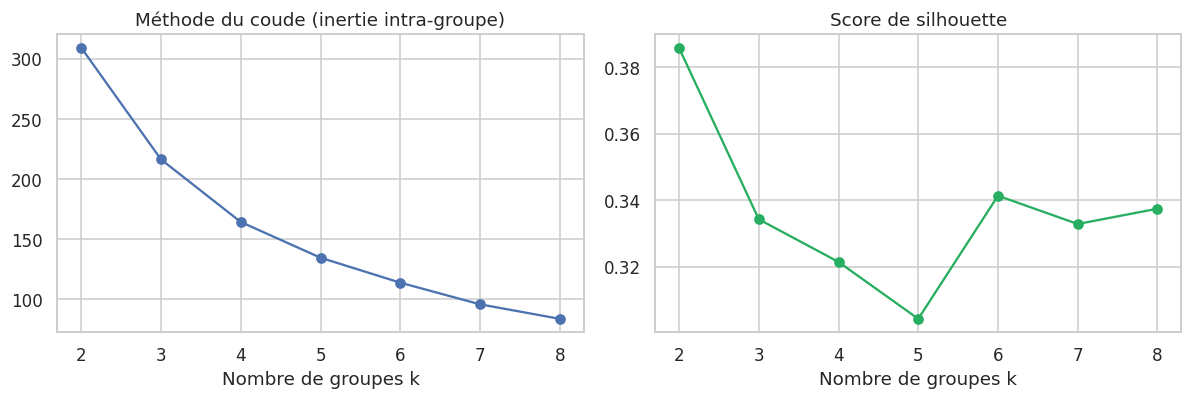

{2: 0.39, 3: 0.33, 4: 0.32, 5: 0.3, 6: 0.34, 7: 0.33, 8: 0.34}


In [22]:
Z = coords[["CP1", "CP2", "CP3"]].values
ks = range(2, 9)
inerties, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(Z)
    inerties.append(km.inertia_); silhouettes.append(silhouette_score(Z, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(list(ks), inerties, marker="o"); axes[0].set_title("Méthode du coude (inertie intra-groupe)")
axes[1].plot(list(ks), silhouettes, marker="o", color="#27ae60"); axes[1].set_title("Score de silhouette")
for a in axes: a.set_xlabel("Nombre de groupes k")
plt.tight_layout(); plt.show()
print({k: round(s, 2) for k, s in zip(ks, silhouettes)})

Aucun critère n'est parfait : le coude suggère un k modéré, la silhouette favorise souvent peu de groupes. On retient **k = 4**, un compromis entre qualité statistique et **interprétabilité** (deux groupes seraient trop grossiers pour raconter quelque chose).

### 9.2 Les groupes obtenus

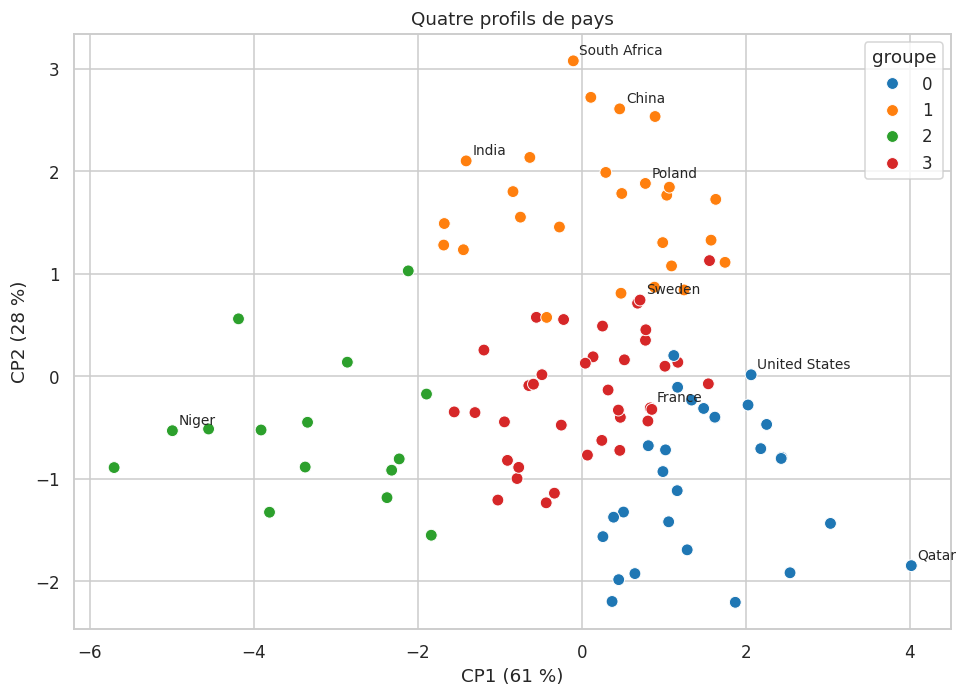

In [23]:
k = 4
km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(Z)
coords["groupe"] = km.labels_

fig, ax = plt.subplots(figsize=(9, 6.5))
sns.scatterplot(data=coords, x="CP1", y="CP2", hue="groupe", palette="tab10", s=60, ax=ax)
for nom in etiquettes:
    if nom in coords.index:
        ax.annotate(nom, (coords.loc[nom, "CP1"], coords.loc[nom, "CP2"]), fontsize=9, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel(f"CP1 ({var[0]:.0f} %)"); ax.set_ylabel(f"CP2 ({var[1]:.0f} %)")
ax.set_title("Quatre profils de pays"); plt.tight_layout(); plt.show()

In [24]:
profil = acp_df.join(coords["groupe"]).groupby("groupe").agg(
    n=("log_pib_hab", "size"),
    pib_hab=("log_pib_hab", lambda s: round(10**s.median())),
    co2_hab=("log_co2_hab", lambda s: round(10**s.median(), 1)),
    part_charbon_pct=("part_charbon", lambda s: round(s.median() * 100)),
    part_gaz_pct=("part_gaz", lambda s: round(s.median() * 100)),
)
profil["exemples"] = coords.groupby("groupe").apply(lambda g: ", ".join(g.index[:6]))
profil.sort_values("pib_hab")

,n,pib_hab,co2_hab,part_charbon_pct,part_gaz_pct,exemples
groupe,,,,,,
2,15,2419,0.4,9,5,"Afghanistan, Bangladesh, Benin, Democratic Rep..."
1,26,19586,6.5,53,11,"Australia, Bosnia and Herzegovina, Botswana, B..."
3,37,22929,3.8,8,20,"Albania, Austria, Bolivia, Brazil, Chile, Colo..."
0,28,36404,7.3,7,44,"Algeria, Argentina, Armenia, Azerbaijan, Belar..."


**À vous d'interpréter** : à partir des médianes, donnez un nom à chaque groupe (par exemple « pays à faible revenu, peu émetteurs », « économies charbonnées », « pays riches à mix diversifié »…). Une méthode de clustering ne vaut que par l'interprétation qu'on en fait.

## 10. Random forest : peut-on prédire quels pays vont découpler ?

Dernière question, prédictive cette fois : **les caractéristiques d'un pays en 2005 permettent-elles de prédire s'il sera en découplage absolu en 2022 ?**

- **Cible** : 1 si le pays est en découplage absolu (PIB ↑, CO₂ ↓), 0 sinon. On ne garde que les pays dont le PIB a augmenté.
- **Variables explicatives** : richesse, émissions, énergie et mix fossile **en 2005 uniquement**. Toute information postérieure à 2005 est exclue : sinon, le modèle « tricherait » en voyant une partie de ce qu'il doit prédire (voir 10.2).

La cible utilise bien 2022 : c'est normal. En apprentissage supervisé, on entraîne le modèle sur des cas dont on connaît déjà l'issue.

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

t = (pays[pays["year"].isin([2005, 2022])]
     .pivot_table(index="country", columns="year",
                  values=["gdp", "co2", "population", "pib_par_hab", "co2_per_capita",
                          "energy_per_capita", "part_charbon", "part_petrole", "part_gaz"]))
t = t.dropna(subset=[("gdp", 2005), ("gdp", 2022), ("co2", 2005), ("co2", 2022)])
t = t[t["gdp"][2022] > t["gdp"][2005]]                     # pays dont le PIB a augmenté

X_rf = pd.DataFrame({
    "log_pib_hab_2005": np.log10(t["pib_par_hab"][2005]),
    "log_co2_hab_2005": np.log10(t["co2_per_capita"][2005]),
    "log_energie_hab_2005": np.log10(t["energy_per_capita"][2005]),
    "part_charbon_2005": t["part_charbon"][2005],
    "part_petrole_2005": t["part_petrole"][2005],
    "part_gaz_2005": t["part_gaz"][2005],
}).replace([np.inf, -np.inf], np.nan)
y_rf = (t["co2"][2022] < t["co2"][2005]).astype(int)

ok = X_rf.notna().all(axis=1)
X_rf, y_rf = X_rf[ok], y_rf[ok]
print(f"{len(X_rf)} pays, dont {y_rf.sum()} en découplage absolu ({y_rf.mean() * 100:.0f} %)")

91 pays, dont 40 en découplage absolu (44 %)


**Méthode d'évaluation** : avec moins de 100 pays, un simple découpage apprentissage/test serait très instable. On utilise une **validation croisée stratifiée à 5 plis** : chaque pays est prédit par un modèle qui ne l'a jamais vu. On compare au modèle naïf qui prédit toujours la classe majoritaire.

Exactitude du modèle naïf : 0.56
Exactitude random forest  : 0.76
Exactitude équilibrée     : 0.77
AUC ROC                   : 0.88


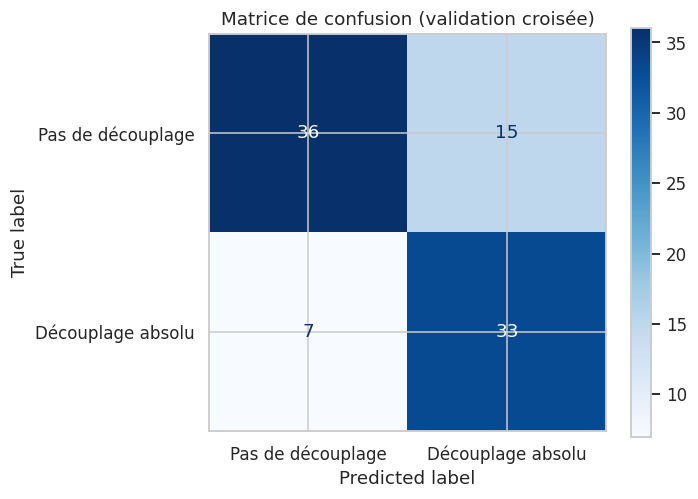

In [26]:
rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight="balanced", random_state=0)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
proba = cross_val_predict(rf, X_rf, y_rf, cv=cv, method="predict_proba")[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"Exactitude du modèle naïf : {max(y_rf.mean(), 1 - y_rf.mean()):.2f}")
print(f"Exactitude random forest  : {(pred == y_rf).mean():.2f}")
print(f"Exactitude équilibrée     : {balanced_accuracy_score(y_rf, pred):.2f}")
print(f"AUC ROC                   : {roc_auc_score(y_rf, proba):.2f}")

ConfusionMatrixDisplay(confusion_matrix(y_rf, pred),
                       display_labels=["Pas de découplage", "Découplage absolu"]).plot(cmap="Blues")
plt.title("Matrice de confusion (validation croisée)"); plt.tight_layout(); plt.show()

### 10.1 Quelles variables comptent ?

On mesure l'**importance par permutation** : on mélange une variable au hasard et on regarde de combien l'AUC baisse. Plus la baisse est forte, plus le modèle s'appuie sur cette variable.

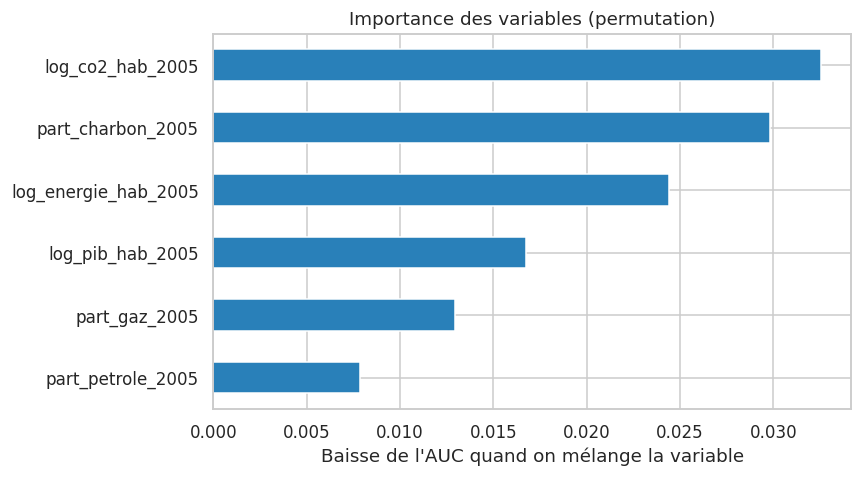

In [27]:
rf.fit(X_rf, y_rf)
imp = permutation_importance(rf, X_rf, y_rf, n_repeats=30, random_state=0, scoring="roc_auc")
importances = pd.Series(imp.importances_mean, index=X_rf.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
importances.plot.barh(ax=ax, color="#2980b9")
ax.set_xlabel("Baisse de l'AUC quand on mélange la variable")
ax.set_title("Importance des variables (permutation)"); plt.tight_layout(); plt.show()

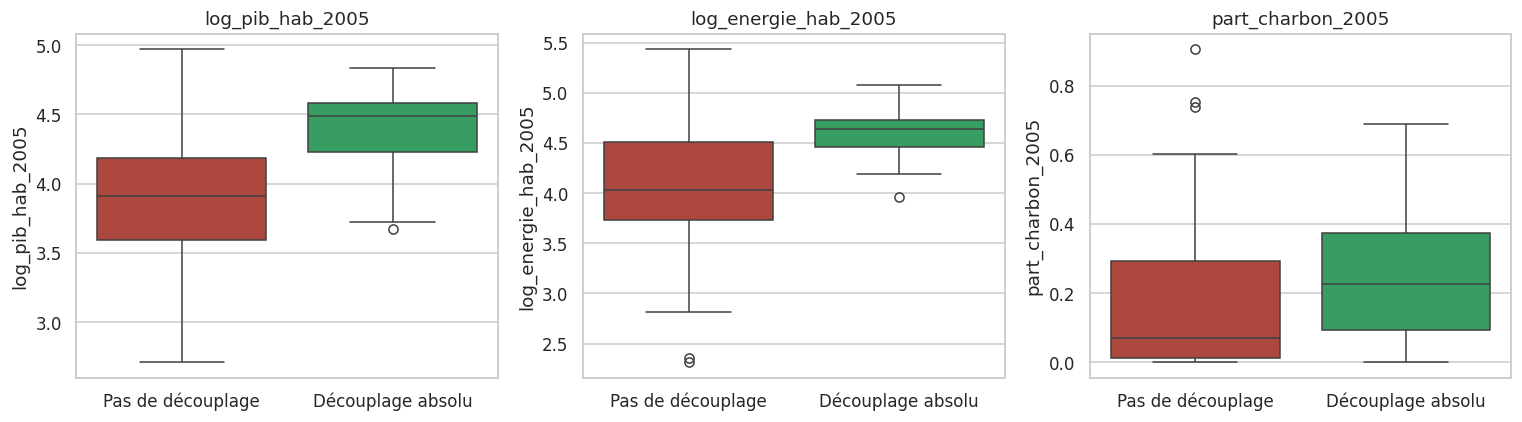

In [28]:
etiq = y_rf.map({0: "Pas de découplage", 1: "Découplage absolu"})
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["log_pib_hab_2005", "log_energie_hab_2005", "part_charbon_2005"]):
    sns.boxplot(x=etiq, y=X_rf[col], hue=etiq, ax=ax, palette=["#c0392b", "#27ae60"], legend=False)
    ax.set_xlabel(""); ax.set_title(col)
plt.tight_layout(); plt.show()

### 10.2 Le piège de la fuite d'information (*data leakage*)

Une première version de ce modèle ajoutait deux variables : la **croissance du PIB** et la **croissance de la population entre 2005 et 2022**. Elles semblent anodines, mais elles ne sont pas connues en 2005 : le modèle voyait donc une partie de la période qu'il devait prédire. La croissance du PIB est en plus liée mécaniquement à la cible (plus l'économie grossit vite, plus il est difficile de baisser les émissions en valeur absolue).

Comparons les deux versions :

In [29]:
X_fuite = X_rf.assign(
    croissance_pib_pct=(t["gdp"][2022] / t["gdp"][2005] - 1)[X_rf.index] * 100,
    croissance_pop_pct=(t["population"][2022] / t["population"][2005] - 1)[X_rf.index] * 100,
)
resultats = {}
for nom, X in [("Variables de 2005 uniquement", X_rf), ("Avec croissances 2005-2022 (fuite)", X_fuite)]:
    p = cross_val_predict(rf, X, y_rf, cv=cv, method="predict_proba")[:, 1]
    resultats[nom] = {"exactitude": ((p >= 0.5) == y_rf).mean(), "AUC": roc_auc_score(y_rf, p)}
pd.DataFrame(resultats).T.round(2)

,exactitude,AUC
Variables de 2005 uniquement,0.76,0.88
Avec croissances 2005-2022 (fuite),0.84,0.92


La version avec fuite affiche de meilleurs scores, mais ils sont **trompeurs** : ce modèle serait inutilisable en 2005, puisqu'il a besoin de données de 2022. La bonne question à se poser pour chaque variable : *est-ce que je la connaîtrais au moment où je fais la prédiction ?*

**Interprétation** :
- Le modèle fait nettement mieux que le modèle naïf : le découplage n'est pas aléatoire, il dépend du profil du pays.
- Les boîtes à moustaches montrent le sens des effets : en 2005, les pays qui allaient découpler étaient déjà **riches** (PIB médian ≈ 31 000 $ par habitant contre ≈ 8 000 $), **gros émetteurs** (≈ 8 t de CO₂ par habitant contre ≈ 2 t) et plus **dépendants du charbon** (23 % de leur CO₂ contre 7 %). Autrement dit, ceux qui découplent sont ceux qui avaient le plus de marge pour réduire, notamment en sortant du charbon.

⚠️ **Limites propres au modèle** :
- Petit échantillon (≈ 90 pays) : les résultats varient selon le découpage, d'où la validation croisée.
- L'importance d'une variable n'est pas un effet causal : elle indique sur quoi le modèle s'appuie, pas ce qui provoque le découplage.
- Ici, le random forest est un outil d'**exploration** : il sert à repérer des facteurs, pas à prévoir l'avenir d'un pays.

## 11. Conclusions et limites

**Messages clés pour la présentation** :
1. Les émissions mondiales ont augmenté d'environ 70 % depuis 1990.
2. À l'échelle d'un instant donné, richesse et émissions par habitant sont très liées (r ≈ 0,9).
3. Mais 45 pays ont réussi à faire croître leur PIB tout en baissant leurs émissions entre 2005 et 2022, dont la France.
4. Pour près d'un tiers de ces pays, la baisse disparaît quand on compte les émissions importées : il faut regarder la consommation, pas seulement la production.
5. Les pays se répartissent en profils distincts (ACP et clustering), et un random forest prédit bien le découplage à partir de la seule situation de 2005 (AUC 0,88) : il concerne surtout des pays déjà riches et gros émetteurs, qui avaient le plus de marge de réduction.
6. Réponse à la question : **le découplage est possible**, mais il reste trop lent pour faire baisser les émissions mondiales, tirées par la croissance des pays émergents.

**Limites** :
- PIB disponible pour 164 pays seulement, jusqu'en 2022 ; émissions de consommation pour environ 120 pays.
- Le choix des années (2005 et 2022) influence les résultats (crises, Covid…). Un test de robustesse sur d'autres périodes serait utile.
- Le CO₂ n'est qu'une partie des gaz à effet de serre (méthane, protoxyde d'azote non étudiés).
- Les méthodes multivariées (ACP, clustering, random forest) ne portent que sur une centaine de pays, faute de données complètes.
- Corrélation n'est pas causalité : la richesse n'« explique » pas les émissions à elle seule (mix énergétique, géographie, industrie…).